# Inferencia

Generación de predicciones de `SalePrice` para los datos crudos de `test.csv` con el modelo `champion` registrado en MLflow por el notebook `3.0` (pipeline de ingeniería de características + modelo). El flujo se ejecuta primero paso a paso y luego se encapsula en un único objeto, `InferencePipeline`, que recibe datos crudos y devuelve el precio en dólares.

| Paso | Descripción |
|---|---|
| 1 | Selección de las columnas de `MODEL_FEATURES` |
| 2 | Preprocesamiento y predicción con el modelo champion (escala log) |
| 3 | Reversión del target a escala real con `expm1` |

La ejecución se registra como un run de inferencia en el experimento de MLflow. En este notebook no se reentrena ningún componente: todos los parámetros provienen del ajuste realizado con el split de entrenamiento.

## 1. Librerías

Carga de librerías, MLflow, rutas del proyecto y de la clase `InferencePipeline` definida en `house_pricing_a/modeling/predict.py`.

In [1]:
# Librerías
import joblib
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from mlflow import MlflowClient

from house_pricing_a.config import MODELS_DIR, PROCESSED_DATA_DIR, PROJ_ROOT, RAW_DATA_DIR
from house_pricing_a.modeling.predict import InferencePipeline

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

/opt/anaconda3/envs/env_house_pricing_a/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-11-10 19:14:24.551 | INFO     | house_pricing_a.config:<module>:11 - PROJ_ROOT path is: /Users/prengbiba/Dropbox/Compu/Clases/Postgrado/PAPD/L/Data Product Development/2026/house_pricing_A


## 2. Carga de datos y configuración

Lectura de `test.csv` crudo, sin ninguna transformación previa, y de la lista de features en `pipeline_config.yaml`. La columna `Id` se usa como índice para asociar cada predicción con su registro.

In [2]:
# Rutas y parámetros: ajustar si cambia la fuente
DATA_DIR = RAW_DATA_DIR
TRAIN_FILE = "train.csv"
TEST_FILE = "test.csv"
PIPELINE_CONFIG_PATH = PROJ_ROOT / "pipeline_config.yaml"
PIPELINE_INFERENCIA_PATH = MODELS_DIR / "pipeline_inferencia.joblib"
PREDICTIONS_PATH = PROCESSED_DATA_DIR / "predictions.csv"

# MLflow: mismo backend, experimento y modelo registrado que el notebook 3.0
MLFLOW_TRACKING_URI = f"sqlite:///{PROJ_ROOT / 'mlflow.db'}"
MLFLOW_ARTIFACTS_DIR = PROJ_ROOT / "mlruns"
MLFLOW_EXPERIMENT = "house_pricing_a"
REGISTERED_MODEL_NAME = "house_pricing_a"
MODEL_ALIAS = "champion"

TARGET = "SalePrice"
ID_COL = "Id"

with open(PIPELINE_CONFIG_PATH) as f:
    pipeline_config = yaml.safe_load(f)
MODEL_FEATURES = pipeline_config["MODEL_FEATURES"]

test = pd.read_csv(DATA_DIR / TEST_FILE, index_col=ID_COL)
print(f"test: {test.shape} | features del modelo: {len(MODEL_FEATURES)}")
print(f"Faltantes en las features del modelo: {test[MODEL_FEATURES].isna().sum().sum()}")

test: (1459, 79) | features del modelo: 30
Faltantes en las features del modelo: 1297


## 3. Carga del modelo champion

Carga desde el Model Registry de MLflow de la versión con alias `champion`, registrada por el notebook `3.0`: pasos de ingeniería de características seguidos del modelo entrenado. Se identifica la versión y el algoritmo cargados para dejarlos en el run de inferencia.

El modelo se carga con `mlflow.sklearn.load_model`, que devuelve el pipeline de scikit-learn original. La carga genérica `mlflow.pyfunc` no se usa porque valida los tipos contra la firma de entrenamiento y `test.csv` trae faltantes en columnas que en entrenamiento son enteras.

In [3]:
# Modelo champion desde el Model Registry
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
client = MlflowClient()

MODEL_URI = f"models:/{REGISTERED_MODEL_NAME}@{MODEL_ALIAS}"
version_champion = client.get_model_version_by_alias(REGISTERED_MODEL_NAME, MODEL_ALIAS)
modelo_ganador = mlflow.sklearn.load_model(MODEL_URI)

print(f"Modelo: {MODEL_URI} -> versión {version_champion.version}")
print(f"Algoritmo: {version_champion.tags.get('modelo')} | alias: {version_champion.aliases}")
print(f"Pasos: {list(modelo_ganador.named_steps)}")
modelo_ganador

Modelo: models:/house_pricing_a@champion -> versión 1
Algoritmo: Gradient Boosting | alias: ['champion', 'gradient_boosting']
Pasos: ['imputacion_numericas', 'imputacion_categoricas', 'codificacion', 'outliers', 'transformacion', 'escalado', 'modelo']


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputacion_numericas', ...), ('imputacion_categoricas', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0",list,"['Gr...ea', 'Ga...ea', 'To...SF', '1s...SF', ...]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,variables,"['GrLivArea', 'GarageArea', ...]"
,imputation_method,'median'
Name,Type,Value
feature_names_in_,list,"['Gr...ea', 'Ga...ea', 'To...SF', '1s...SF', ...]"


## 4. Inferencia paso a paso

Ejecución explícita de cada etapa del flujo sobre los datos crudos de test: selección de features, predicción en escala log y reversión a dólares con `expm1`.

In [4]:
# 1) Selección de features
X_test = test[MODEL_FEATURES]

# 2) Preprocesamiento + predicción en escala log
pred_log = modelo_ganador.predict(X_test)

# 3) Reversión a escala real
pred_real = np.expm1(pred_log)

pd.Series(pred_real, index=X_test.index, name=TARGET).describe().to_frame().style.format("{:,.0f}")

,SalePrice
count,"1,459"
mean,"177,342"
std,"75,442"
min,"46,009"
25%,"126,408"
50%,"157,325"
75%,"207,437"
max,"513,808"


## 5. Pipeline de inferencia

Encapsulación del flujo anterior en `InferencePipeline`, un estimador compatible con scikit-learn que recibe datos crudos con cualquier conjunto de columnas y devuelve `SalePrice` en dólares. No se reentrena: envuelve el modelo ganador ya ajustado. Se verifica que sus predicciones coinciden con las del paso a paso y se guarda en `models/`.

In [5]:
# Pipeline de inferencia: datos crudos -> SalePrice en dólares
pipeline_inferencia = InferencePipeline(model=modelo_ganador, features=MODEL_FEATURES, inverse_func=np.expm1)

np.testing.assert_allclose(pipeline_inferencia.predict(test), pred_real)
print("El pipeline de inferencia reproduce el resultado paso a paso.")

joblib.dump(pipeline_inferencia, PIPELINE_INFERENCIA_PATH)
print(f"Pipeline de inferencia guardado en {PIPELINE_INFERENCIA_PATH}")

El pipeline de inferencia reproduce el resultado paso a paso.
Pipeline de inferencia guardado en /Users/prengbiba/Dropbox/Compu/Clases/Postgrado/PAPD/L/Data Product Development/2026/house_pricing_A/models/pipeline_inferencia.joblib


## 6. Generación de predicciones

Carga del pipeline de inferencia desde disco, predicción sobre `test.csv` crudo y almacenamiento en `data/processed/predictions.csv` con el formato de `sample_submission.csv` (`Id`, `SalePrice`).

In [6]:
# Predicciones finales con el pipeline guardado
pipeline_inferencia = joblib.load(PIPELINE_INFERENCIA_PATH)

predictions = pd.DataFrame({TARGET: pipeline_inferencia.predict(test)}, index=test.index)
predictions.to_csv(PREDICTIONS_PATH)

print(f"{len(predictions)} predicciones guardadas en {PREDICTIONS_PATH}")
predictions.head()

1459 predicciones guardadas en /Users/prengbiba/Dropbox/Compu/Clases/Postgrado/PAPD/L/Data Product Development/2026/house_pricing_A/data/processed/predictions.csv


,SalePrice
Id,
1461,123376.422681
1462,148289.409798
1463,186300.604523
1464,192293.578788
1465,192015.834433


## 7. Distribución de las predicciones vs `SalePrice` de entrenamiento

Comparación, en una misma gráfica, de la densidad de `SalePrice` observado en `train.csv` y de los precios producidos por el pipeline de inferencia sobre `test.csv`. Distribuciones similares en forma, centro y rango indican que el pipeline genera predicciones coherentes con los datos de entrenamiento. `train.csv` se usa solo como referencia visual.

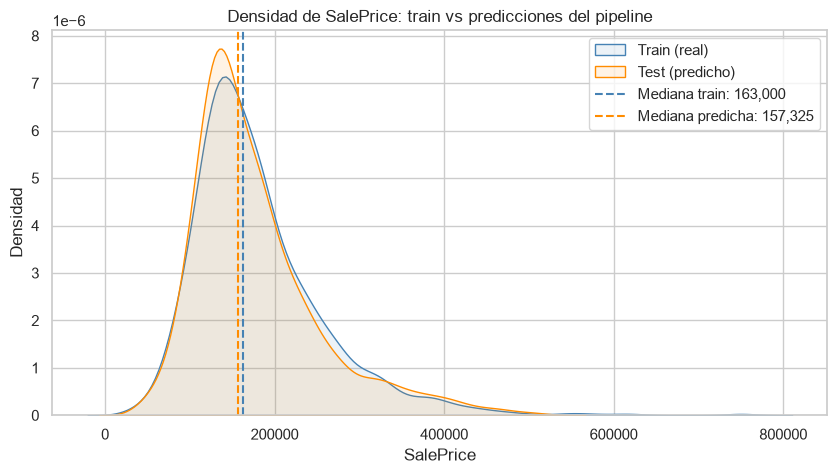

In [7]:
# Densidad: SalePrice de train vs SalePrice predicho en test
train_target = pd.read_csv(DATA_DIR / TRAIN_FILE, index_col=ID_COL)[TARGET]

fig_densidad, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(x=train_target, fill=True, alpha=0.1, color="steelblue", label="Train (real)", ax=ax)
sns.kdeplot(x=predictions[TARGET], fill=True, alpha=0.1, color="darkorange", label="Test (predicho)", ax=ax)
ax.axvline(train_target.median(), color="steelblue", linestyle="--", label=f"Mediana train: {train_target.median():,.0f}")
ax.axvline(predictions[TARGET].median(), color="darkorange", linestyle="--", label=f"Mediana predicha: {predictions[TARGET].median():,.0f}")
ax.set_title(f"Densidad de {TARGET}: train vs predicciones del pipeline")
ax.set_xlabel(TARGET)
ax.set_ylabel("Densidad")
ax.legend()
plt.show()

## 8. Registro de la inferencia en MLflow

Run `inferencia` en el experimento `house_pricing_a`, con la trazabilidad de qué modelo produjo las predicciones:

| Tipo | Contenido |
|---|---|
| Parámetros | URI del modelo, versión, algoritmo, archivo de entrada y número de registros |
| Métricas | Estadísticas de las predicciones (media, mediana, desviación, mínimo, máximo) y cantidad de predicciones negativas o faltantes |
| Artefactos | `predictions.csv` y la gráfica de densidad de la sección 7 |

El run se vincula con la versión del modelo mediante el tag `model_version`.

In [8]:
# Run de inferencia
if mlflow.get_experiment_by_name(MLFLOW_EXPERIMENT) is None:
    mlflow.create_experiment(MLFLOW_EXPERIMENT, artifact_location=MLFLOW_ARTIFACTS_DIR.as_uri())
mlflow.set_experiment(MLFLOW_EXPERIMENT)

pred = predictions[TARGET]

with mlflow.start_run(run_name="inferencia") as run_inferencia:
    mlflow.set_tags({
        "etapa": "inferencia",
        "modelo": version_champion.tags.get("modelo"),
        "model_version": version_champion.version,
    })
    mlflow.log_params({
        "model_uri": MODEL_URI,
        "model_version": version_champion.version,
        "modelo": version_champion.tags.get("modelo"),
        "archivo_entrada": TEST_FILE,
        "n_registros": len(test),
    })
    mlflow.log_metrics({
        "pred_media": pred.mean(),
        "pred_mediana": pred.median(),
        "pred_std": pred.std(),
        "pred_min": pred.min(),
        "pred_max": pred.max(),
        "pred_negativas": int((pred < 0).sum()),
        "pred_faltantes": int(pred.isna().sum()),
    })
    mlflow.log_artifact(str(PREDICTIONS_PATH))
    mlflow.log_figure(fig_densidad, "densidad_train_vs_predicciones.png")

print(f"Run de inferencia: {run_inferencia.info.run_id}")

Run de inferencia: 7b171b3969f14a9caa64a2dc230680fd
